# Transformer Model for Long-Horizon Forecasting

Course: ELE680 – Deep Neural Networks
Group: 2
Dataset: ETTh1
Input sequence length: 96 hours
Prediction horizons: 96, 336 and 720 hours
Target variable: Oil Temperature (OT)

Research question:
Does increasing model complexity improve long-horizon forecasting performance?


In [1]:

# Cell 1: Import libraries and prepare the Transformer experiment.

import os
import time
import random
import math
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Use the university GPU when available.
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Use one fixed seed for reproducible experiments.
SEED = 42

def set_seed(seed=SEED):
    """Reset random generators before creating each new model."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Set the initial seed for this notebook.
set_seed()

# Create folders if they do not already exist.
RESULTS_DIR = "results"
FIGURES_DIR = "figures"
MODELS_DIR = "saved_models"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# Display the environment being used.
print("PyTorch version:", torch.__version__)
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Random seed:", SEED)
print("Setup completed successfully.")


PyTorch version: 2.5.1+cu118
Selected device: cuda:0
GPU: Tesla P100-PCIE-12GB
Random seed: 42
Setup completed successfully.


In [2]:

# Cell 2: Load the preprocessed ETTh1 datasets.
# We reuse our prepared data instead of preprocessing it again.

from pathlib import Path

DATA_DIR = Path("processed_data")

DATA_FILES = {
    96: DATA_DIR / "ETTh1_preprocessed.pt",
    336: DATA_DIR / "ETTh1_336h_preprocessed.pt",
    720: DATA_DIR / "ETTh1_720h_preprocessed.pt",
}

# Check that all three files exist before loading them.
for horizon, file_path in DATA_FILES.items():
    print(f"{horizon}-hour forecast file: {file_path}")
    print("  Exists:", file_path.exists())

# Load each file onto the CPU first.
# weights_only=False is needed if the files contain saved Python objects.
# Only load files from your trusted project.
datasets = {}

for horizon, file_path in DATA_FILES.items():
    if not file_path.exists():
        raise FileNotFoundError(f"Missing preprocessed data file: {file_path}")

    datasets[horizon] = torch.load(
        file_path,
        map_location="cpu",
        weights_only=False
    )

print("\nAll three dataset files loaded successfully.")
print("Loaded forecast horizons:", list(datasets.keys()))



96-hour forecast file: processed_data/ETTh1_preprocessed.pt
  Exists: True
336-hour forecast file: processed_data/ETTh1_336h_preprocessed.pt
  Exists: True
720-hour forecast file: processed_data/ETTh1_720h_preprocessed.pt
  Exists: True

All three dataset files loaded successfully.
Loaded forecast horizons: [96, 336, 720]


In [3]:

# Cell 3: Inspect the preprocessed data for each forecast horizon.
# We need to confirm the tensor shapes before building the Transformer.

for horizon, data in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"Forecast horizon: {horizon} hours")
    print(f"{'=' * 50}")

    # Show the keys stored in the preprocessed file.
    print("Saved keys:", list(data.keys()))

    # Display the shapes of the training, validation and test tensors.
    for key in ["X_train", "y_train", "X_val", "y_val", "X_test", "y_test"]:
        if key in data:
            value = data[key]
            print(f"{key}: {tuple(value.shape)}")

    # Display the forecast metadata if it is available.
    for key in ["input_len", "pred_len", "feature_cols", "target_index"]:
        if key in data:
            print(f"{key}: {data[key]}")



Forecast horizon: 96 hours
Saved keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'feature_cols', 'target_index', 'input_len', 'pred_len', 'ot_mean', 'ot_std']
X_train: (8449, 96, 7)
y_train: (8449, 96)
X_val: (2785, 96, 7)
y_val: (2785, 96)
X_test: (2785, 96, 7)
y_test: (2785, 96)
input_len: 96
pred_len: 96
feature_cols: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
target_index: 6

Forecast horizon: 336 hours
Saved keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'feature_cols', 'target_index', 'input_len', 'pred_len', 'ot_mean', 'ot_std']
X_train: (8209, 96, 7)
y_train: (8209, 336)
X_val: (2545, 96, 7)
y_val: (2545, 336)
X_test: (2545, 96, 7)
y_test: (2545, 336)
input_len: 96
pred_len: 336
feature_cols: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
target_index: 6

Forecast horizon: 720 hours
Saved keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'feature_cols', 'target_index', 'input_len', 'pred_len', 'ot_mean

In [4]:

# Cell 4: Prepare training, validation and test DataLoaders.
# We reuse the preprocessed tensors without changing their values.

BATCH_SIZE = 32

data_loaders = {}

for horizon, data in datasets.items():
    # Convert the saved arrays/tensors to float32 PyTorch tensors.
    X_train = torch.as_tensor(data["X_train"], dtype=torch.float32)
    y_train = torch.as_tensor(data["y_train"], dtype=torch.float32)

    X_val = torch.as_tensor(data["X_val"], dtype=torch.float32)
    y_val = torch.as_tensor(data["y_val"], dtype=torch.float32)

    X_test = torch.as_tensor(data["X_test"], dtype=torch.float32)
    y_test = torch.as_tensor(data["y_test"], dtype=torch.float32)

    # DataLoader groups examples into batches for model training.
    # Shuffle training examples, but keep validation and test order unchanged.
    data_loaders[horizon] = {
        "train": DataLoader(
            TensorDataset(X_train, y_train),
            batch_size=BATCH_SIZE,
            shuffle=True
        ),
        "val": DataLoader(
            TensorDataset(X_val, y_val),
            batch_size=BATCH_SIZE,
            shuffle=False
        ),
        "test": DataLoader(
            TensorDataset(X_test, y_test),
            batch_size=BATCH_SIZE,
            shuffle=False
        )
    }

    # Report the number of batches and confirm the input/target shapes.
    print(f"\nForecast horizon: {horizon} hours")
    print("Training batches:", len(data_loaders[horizon]["train"]))
    print("Validation batches:", len(data_loaders[horizon]["val"]))
    print("Test batches:", len(data_loaders[horizon]["test"]))
    print("Input shape:", tuple(X_train.shape[1:]))
    print("Target shape:", tuple(y_train.shape[1:]))



Forecast horizon: 96 hours
Training batches: 265
Validation batches: 88
Test batches: 88
Input shape: (96, 7)
Target shape: (96,)

Forecast horizon: 336 hours
Training batches: 257
Validation batches: 80
Test batches: 80
Input shape: (96, 7)
Target shape: (336,)

Forecast horizon: 720 hours
Training batches: 245
Validation batches: 68
Test batches: 68
Input shape: (96, 7)
Target shape: (720,)


In [5]:

# Cell 5: Transformer model with optional RevIN

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()

        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, 1, d_model)
        pe[:, 0, 0::2] = torch.sin(position * div_term)
        pe[:, 0, 1::2] = torch.cos(
            position * div_term[:pe[:, 0, 1::2].shape[-1]]
        )

        self.register_buffer("pe", pe)

    def forward(self, x):
        # x shape: (sequence length, batch size, features)
        return x + self.pe[:x.size(0)]


class TransformerForecaster(nn.Module):
    def __init__(
        self,
        input_dim=7,
        input_len=96,
        pred_len=96,
        d_model=64,
        n_heads=4,
        num_layers=2,
        dim_feedforward=128,
        dropout=0.1,
        use_revin=False,
        target_index=6,
    ):
        super().__init__()

        self.input_len = input_len
        self.pred_len = pred_len
        self.use_revin = use_revin
        self.target_index = target_index

        self.input_projection = nn.Linear(input_dim, d_model)
        self.positional_encoding = PositionalEncoding(d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=False,
        )

        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
        )

        self.forecast_head = nn.Linear(input_len * d_model, pred_len)

    def forward(self, x):
        # x shape: (batch size, input length, 7 features)

        if self.use_revin:
            # Calculate statistics separately for each input window.
            window_mean = x.mean(dim=1, keepdim=True).detach()
            window_std = (
                x.var(dim=1, keepdim=True, unbiased=False) + 1e-5
            ).sqrt().detach()

            # Normalize each feature using its own window statistics.
            x = (x - window_mean) / window_std

        x = self.input_projection(x)

        # Transformer expects (sequence length, batch size, features).
        x = x.transpose(0, 1)
        x = self.positional_encoding(x)
        x = self.transformer_encoder(x)

        # Flatten the encoded sequence and predict the future OT values.
        x = x.transpose(0, 1)
        x = x.reshape(x.size(0), -1)
        forecast = self.forecast_head(x)

        if self.use_revin:
            # Return the OT forecast to the input window's original scale.
            ot_mean = window_mean[:, :, self.target_index]
            ot_std = window_std[:, :, self.target_index]
            forecast = forecast * ot_std + ot_mean

        return forecast


MODEL_CONFIG = {
    "d_model": 64,
    "n_heads": 4,
    "num_layers": 2,
    "dim_feedforward": 128,
    "dropout": 0.1,
}

VARIANTS = {
    "Transformer": {"use_revin": False},
    "Transformer + RevIN": {"use_revin": True},
}

print("Transformer model definitions loaded.")
print("Available variants:", list(VARIANTS.keys()))


Transformer model definitions loaded.
Available variants: ['Transformer', 'Transformer + RevIN']


In [6]:

# Cell 6: Training configuration

LR_CANDIDATES = [0.001, 0.0001]

BATCH_SIZE = 32
MAX_EPOCHS = 30
PATIENCE = 5

criterion = nn.MSELoss()

def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

print("Device:", device)
print("Batch size:", BATCH_SIZE)
print("Learning rates to compare:", LR_CANDIDATES)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Loss function: Mean Squared Error (MSE)")
print("Optimizer: Adam")


Device: cuda:0
Batch size: 32
Learning rates to compare: [0.001, 0.0001]
Maximum epochs: 30
Early stopping patience: 5
Loss function: Mean Squared Error (MSE)
Optimizer: Adam


In [7]:

# Cell 7: Training and validation functions

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = X_batch.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


def train_model(
    model,
    train_loader,
    val_loader,
    learning_rate,
    checkpoint_path,
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE,
):
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
    )

    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    train_losses = []
    val_losses = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.time()

    for epoch in range(1, max_epochs + 1):
        train_loss = run_epoch(
            model,
            train_loader,
            optimizer=optimizer,
        )

        val_loss = run_epoch(
            model,
            val_loader,
        )

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save(model.state_dict(), checkpoint_path)
        else:
            epochs_without_improvement += 1

        print(
            f"Epoch {epoch:02d}/{max_epochs} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Validation MSE: {val_loss:.6f}"
        )

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}.")
            break

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_time = time.time() - start_time

    # Restore the best model, not just the final epoch.
    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True,
        )
    )

    history = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_val_mse": best_val_loss,
        "best_epoch": best_epoch,
        "epochs_trained": len(train_losses),
        "training_time_s": training_time,
    }

    return model, history


print("Training and validation functions defined successfully.")


Training and validation functions defined successfully.


In [8]:

# Cell 8: Quick test of both Transformer variants

# Use the 96-hour forecast dataset for the initial test.
horizon = 96

train_loader = data_loaders[horizon]["train"]
X_batch, y_batch = next(iter(train_loader))

# Test with only two examples.
X_batch = X_batch[:2].to(device)
y_batch = y_batch[:2].to(device)

for variant_name, variant_config in VARIANTS.items():
    test_model = TransformerForecaster(
        input_dim=X_batch.shape[-1],
        input_len=X_batch.shape[1],
        pred_len=y_batch.shape[1],
        use_revin=variant_config["use_revin"],
        **MODEL_CONFIG,
    ).to(device)

    test_model.eval()

    with torch.no_grad():
        predictions = test_model(X_batch)

    print(f"\nVariant: {variant_name}")
    print("Input shape:", tuple(X_batch.shape))
    print("Target shape:", tuple(y_batch.shape))
    print("Prediction shape:", tuple(predictions.shape))
    print("Predictions are finite:", torch.isfinite(predictions).all().item())

    assert predictions.shape == y_batch.shape, "Output shape mismatch!"
    assert torch.isfinite(predictions).all(), "Predictions contain NaN or infinity!"

    del test_model

print("\nBoth Transformer variants passed the quick test.")


/home/stud/padha9311/.local/lib/python3.12/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(



Variant: Transformer
Input shape: (2, 96, 7)
Target shape: (2, 96)
Prediction shape: (2, 96)
Predictions are finite: True

Variant: Transformer + RevIN
Input shape: (2, 96, 7)
Target shape: (2, 96)
Prediction shape: (2, 96)
Predictions are finite: True

Both Transformer variants passed the quick test.


In [9]:

# Cell 9: Compare learning rates on the 96-hour forecast

horizon = 96
train_loader = data_loaders[horizon]["train"]
val_loader = data_loaders[horizon]["val"]

lr_selection_results = []
best_learning_rates = {}

for variant_name, variant_config in VARIANTS.items():
    print("\n" + "=" * 65)
    print("Testing variant:", variant_name)
    print("=" * 65)

    best_variant_val_mse = float("inf")
    best_variant_lr = None

    for learning_rate in LR_CANDIDATES:
        print(f"\nTesting learning rate: {learning_rate}")

        # Reset random seeds so experiments start reproducibly.
        set_seed(SEED)

        model = TransformerForecaster(
            input_dim=7,
            input_len=96,
            pred_len=96,
            use_revin=variant_config["use_revin"],
            **MODEL_CONFIG,
        ).to(device)

        checkpoint_path = os.path.join(
            MODELS_DIR,
            f"Transformer_{variant_name.replace(' + ', '_')}_96h_lr{learning_rate}_selection.pt"
        )

        model, history = train_model(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            learning_rate=learning_rate,
            checkpoint_path=checkpoint_path,
        )

        result = {
            "model": variant_name,
            "horizon": horizon,
            "learning_rate": learning_rate,
            "val_mse": history["best_val_mse"],
            "best_epoch": history["best_epoch"],
            "epochs_trained": history["epochs_trained"],
            "training_time_s": history["training_time_s"],
            "checkpoint": checkpoint_path,
        }

        lr_selection_results.append(result)

        print(f"Best validation MSE: {history['best_val_mse']:.6f}")
        print(f"Best epoch: {history['best_epoch']}")

        if history["best_val_mse"] < best_variant_val_mse:
            best_variant_val_mse = history["best_val_mse"]
            best_variant_lr = learning_rate

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    best_learning_rates[variant_name] = best_variant_lr

    print(f"\nSelected learning rate for {variant_name}: {best_variant_lr}")
    print(f"Validation MSE: {best_variant_val_mse:.6f}")

lr_selection_df = pd.DataFrame(lr_selection_results)

print("\nLearning-rate comparison:")
display(
    lr_selection_df[
        ["model", "learning_rate", "val_mse", "best_epoch", "training_time_s"]
    ].sort_values(["model", "val_mse"])
)

print("\nSelected learning rates:")
print(best_learning_rates)



Testing variant: Transformer

Testing learning rate: 0.001
Epoch 01/30 | Train MSE: 0.295882 | Validation MSE: 0.241617
Epoch 02/30 | Train MSE: 0.164575 | Validation MSE: 0.375634
Epoch 03/30 | Train MSE: 0.146751 | Validation MSE: 0.281929
Epoch 04/30 | Train MSE: 0.128357 | Validation MSE: 0.364179
Epoch 05/30 | Train MSE: 0.104355 | Validation MSE: 0.253303
Epoch 06/30 | Train MSE: 0.088767 | Validation MSE: 0.313985
Early stopping at epoch 6.
Best validation MSE: 0.241617
Best epoch: 1

Testing learning rate: 0.0001


/home/stud/padha9311/.local/lib/python3.12/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


Epoch 01/30 | Train MSE: 0.214901 | Validation MSE: 0.177590
Epoch 02/30 | Train MSE: 0.164320 | Validation MSE: 0.196203
Epoch 03/30 | Train MSE: 0.157000 | Validation MSE: 0.224221
Epoch 04/30 | Train MSE: 0.147251 | Validation MSE: 0.213500
Epoch 05/30 | Train MSE: 0.139533 | Validation MSE: 0.217010
Epoch 06/30 | Train MSE: 0.130840 | Validation MSE: 0.276431
Early stopping at epoch 6.
Best validation MSE: 0.177590
Best epoch: 1

Selected learning rate for Transformer: 0.0001
Validation MSE: 0.177590

Testing variant: Transformer + RevIN

Testing learning rate: 0.001
Epoch 01/30 | Train MSE: 0.187379 | Validation MSE: 0.139615
Epoch 02/30 | Train MSE: 0.139270 | Validation MSE: 0.175127
Epoch 03/30 | Train MSE: 0.114611 | Validation MSE: 0.167106
Epoch 04/30 | Train MSE: 0.081859 | Validation MSE: 0.174789
Epoch 05/30 | Train MSE: 0.063544 | Validation MSE: 0.154588
Epoch 06/30 | Train MSE: 0.052820 | Validation MSE: 0.168060
Early stopping at epoch 6.
Best validation MSE: 0.139615

,model,learning_rate,val_mse,best_epoch,training_time_s
1,Transformer,0.0001,0.177590,1,23.721807
0,Transformer,0.0010,0.241617,1,24.242189
3,Transformer + RevIN,0.0001,0.115752,1,21.725653
2,Transformer + RevIN,0.0010,0.139615,1,24.219561



Selected learning rates:
{'Transformer': 0.0001, 'Transformer + RevIN': 0.0001}


In [10]:

# Display the complete learning-rate comparison

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

display(
    lr_selection_df[
        [
            "model",
            "learning_rate",
            "val_mse",
            "best_epoch",
            "epochs_trained",
            "training_time_s",
        ]
    ].sort_values(["model", "val_mse"])
)

print("\nSelected learning rates:")
for model_name, learning_rate in best_learning_rates.items():
    print(f"{model_name}: {learning_rate}")


,model,learning_rate,val_mse,best_epoch,epochs_trained,training_time_s
1,Transformer,0.0001,0.177590,1,6,23.721807
0,Transformer,0.0010,0.241617,1,6,24.242189
3,Transformer + RevIN,0.0001,0.115752,1,6,21.725653
2,Transformer + RevIN,0.0010,0.139615,1,6,24.219561



Selected learning rates:
Transformer: 0.0001
Transformer + RevIN: 0.0001


In [11]:

# Cell 10: Train both Transformer variants for all forecast horizons
# Save the best checkpoints and retain loss histories for plotting.

HORIZONS = [96, 336, 720]
final_training_results = []

for variant_name, variant_config in VARIANTS.items():

    learning_rate = best_learning_rates[variant_name]

    for horizon in HORIZONS:
        print("\n" + "=" * 65)
        print(f"Model: {variant_name}")
        print(f"Forecast horizon: {horizon} hours")
        print(f"Learning rate: {learning_rate}")
        print("=" * 65)

        # Get DataLoaders for this horizon.
        train_loader = data_loaders[horizon]["train"]
        val_loader = data_loaders[horizon]["val"]

        # Reset random seeds before creating each model.
        set_seed(SEED)

        model = TransformerForecaster(
            input_dim=7,
            input_len=96,
            pred_len=horizon,
            use_revin=variant_config["use_revin"],
            **MODEL_CONFIG,
        ).to(device)

        # Keep original Transformer filenames.
        # Save RevIN models separately.
        if variant_name == "Transformer":
            checkpoint_path = os.path.join(
                MODELS_DIR,
                f"Transformer_{horizon}h_best.pt"
            )
        else:
            checkpoint_path = os.path.join(
                MODELS_DIR,
                f"Transformer_RevIN_{horizon}h_best.pt"
            )

        print("Checkpoint:", checkpoint_path)

        # Train and restore the best validation checkpoint.
        model, history = train_model(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            learning_rate=learning_rate,
            checkpoint_path=checkpoint_path,
        )

        # Save training results AND complete loss histories.
        final_training_results.append({
            "model": variant_name,
            "input_len": 96,
            "pred_len": horizon,
            "learning_rate": learning_rate,
            "val_mse": history["best_val_mse"],
            "best_epoch": history["best_epoch"],
            "epochs_trained": history["epochs_trained"],
            "training_time_s": history["training_time_s"],
            "parameters": count_parameters(model),
            "checkpoint": checkpoint_path,
            "train_losses": history["train_losses"],
            "val_losses": history["val_losses"],
        })

        print(f"Best validation MSE: {history['best_val_mse']:.6f}")
        print(f"Best epoch: {history['best_epoch']}")
        print(f"Epochs trained: {history['epochs_trained']}")
        print(f"Training time: {history['training_time_s']:.2f} seconds")
        print("Checkpoint saved successfully.")

        del model

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# Create a DataFrame containing all six training runs.
final_training_df = pd.DataFrame(final_training_results)

print("\nAll six training runs completed.")
display(
    final_training_df[
        [
            "model",
            "pred_len",
            "learning_rate",
            "val_mse",
            "best_epoch",
            "epochs_trained",
            "training_time_s",
            "checkpoint",
        ]
    ].sort_values(["pred_len", "model"]).reset_index(drop=True)
)

print("\nLoss histories retained for all six runs.")



Model: Transformer
Forecast horizon: 96 hours
Learning rate: 0.0001


Checkpoint: saved_models/Transformer_96h_best.pt


/home/stud/padha9311/.local/lib/python3.12/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


Epoch 01/30 | Train MSE: 0.214901 | Validation MSE: 0.177590
Epoch 02/30 | Train MSE: 0.164320 | Validation MSE: 0.196203
Epoch 03/30 | Train MSE: 0.157000 | Validation MSE: 0.224221
Epoch 04/30 | Train MSE: 0.147251 | Validation MSE: 0.213500
Epoch 05/30 | Train MSE: 0.139533 | Validation MSE: 0.217010
Epoch 06/30 | Train MSE: 0.130840 | Validation MSE: 0.276431
Early stopping at epoch 6.
Best validation MSE: 0.177590
Best epoch: 1
Epochs trained: 6
Training time: 20.95 seconds
Checkpoint saved successfully.

Model: Transformer
Forecast horizon: 336 hours
Learning rate: 0.0001
Checkpoint: saved_models/Transformer_336h_best.pt
Epoch 01/30 | Train MSE: 0.229821 | Validation MSE: 0.218029
Epoch 02/30 | Train MSE: 0.178442 | Validation MSE: 0.233247
Epoch 03/30 | Train MSE: 0.166578 | Validation MSE: 0.235737
Epoch 04/30 | Train MSE: 0.158854 | Validation MSE: 0.229066
Epoch 05/30 | Train MSE: 0.148773 | Validation MSE: 0.242974
Epoch 06/30 | Train MSE: 0.143117 | Validation MSE: 0.238439

,model,pred_len,learning_rate,val_mse,best_epoch,epochs_trained,training_time_s,checkpoint
0,Transformer,96,0.0001,0.177590,1,6,20.948432,saved_models/Transformer_96h_best.pt
1,Transformer + RevIN,96,0.0001,0.115752,1,6,24.298556,saved_models/Transformer_RevIN_96h_best.pt
2,Transformer,336,0.0001,0.218029,1,6,19.833604,saved_models/Transformer_336h_best.pt
3,Transformer + RevIN,336,0.0001,0.153605,2,7,27.240859,saved_models/Transformer_RevIN_336h_best.pt
4,Transformer,720,0.0001,0.284155,1,6,21.633390,saved_models/Transformer_720h_best.pt
5,Transformer + RevIN,720,0.0001,0.217121,1,6,22.612501,saved_models/Transformer_RevIN_720h_best.pt



Loss histories retained for all six runs.


In [12]:

# Cell 11: Evaluate all six trained models on validation and test data

test_results = []

for variant_name, variant_config in VARIANTS.items():
    for horizon in HORIZONS:

        print(f"Evaluating {variant_name} — {horizon} hours")

        if variant_name == "Transformer":
            checkpoint_path = os.path.join(
                MODELS_DIR,
                f"Transformer_{horizon}h_best.pt"
            )
        else:
            checkpoint_path = os.path.join(
                MODELS_DIR,
                f"Transformer_RevIN_{horizon}h_best.pt"
            )

        model = TransformerForecaster(
            input_dim=7,
            input_len=96,
            pred_len=horizon,
            use_revin=variant_config["use_revin"],
            **MODEL_CONFIG,
        ).to(device)

        model.load_state_dict(
            torch.load(
                checkpoint_path,
                map_location=device,
                weights_only=True,
            )
        )
        model.eval()

        # Evaluate on validation data.
        val_se, val_ae, val_n = 0.0, 0.0, 0

        with torch.no_grad():
            for X_batch, y_batch in data_loaders[horizon]["val"]:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                error = model(X_batch) - y_batch

                val_se += error.pow(2).sum().item()
                val_ae += error.abs().sum().item()
                val_n += y_batch.numel()

        val_mse = val_se / val_n
        val_mae = val_ae / val_n

        # Evaluate on test data.
        test_se, test_ae, test_n = 0.0, 0.0, 0

        with torch.no_grad():
            for X_batch, y_batch in data_loaders[horizon]["test"]:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                error = model(X_batch) - y_batch

                test_se += error.pow(2).sum().item()
                test_ae += error.abs().sum().item()
                test_n += y_batch.numel()

        test_mse = test_se / test_n
        test_mae = test_ae / test_n

        # Retrieve the training information for this model.
        matching_row = final_training_df[
            (final_training_df["model"] == variant_name)
            & (final_training_df["pred_len"] == horizon)
        ].iloc[0]

        test_results.append({
            "model": variant_name,
            "input_len": 96,
            "pred_len": horizon,
            "learning_rate": matching_row["learning_rate"],
            "val_mse": val_mse,
            "val_mae": val_mae,
            "test_mse": test_mse,
            "test_mae": test_mae,
            "parameters": matching_row["parameters"],
            "best_epoch": matching_row["best_epoch"],
            "epochs_trained": matching_row["epochs_trained"],
            "training_time_s": matching_row["training_time_s"],
            "checkpoint": checkpoint_path,
        })

        print(f"Validation MSE: {val_mse:.6f}")
        print(f"Validation MAE: {val_mae:.6f}")
        print(f"Test MSE:       {test_mse:.6f}")
        print(f"Test MAE:       {test_mae:.6f}")

        del model

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

test_results_df = pd.DataFrame(test_results)

print("\nFinal Transformer and RevIN comparison:")
display(
    test_results_df[
        [
            "model",
            "pred_len",
            "learning_rate",
            "val_mse",
            "val_mae",
            "test_mse",
            "test_mae",
        ]
    ].sort_values(["pred_len", "model"]).reset_index(drop=True)
)


Evaluating Transformer — 96 hours


/home/stud/padha9311/.local/lib/python3.12/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


Validation MSE: 0.177590
Validation MAE: 0.337791
Test MSE:       0.359840
Test MAE:       0.532816
Evaluating Transformer — 336 hours


/home/stud/padha9311/.local/lib/python3.12/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


Validation MSE: 0.218029
Validation MAE: 0.381645
Test MSE:       0.355421
Test MAE:       0.514123
Evaluating Transformer — 720 hours


...

/home/stud/padha9311/.local/lib/python3.12/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


Validation MSE: 0.153605
Validation MAE: 0.300240
Test MSE:       0.091872
Test MAE:       0.236748
Evaluating Transformer + RevIN — 720 hours


/home/stud/padha9311/.local/lib/python3.12/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


Validation MSE: 0.217121
Validation MAE: 0.363977
Test MSE:       0.128817
Test MAE:       0.282477

Final Transformer and RevIN comparison:


,model,pred_len,learning_rate,val_mse,val_mae,test_mse,test_mae
0,Transformer,96,0.0001,0.177590,0.337791,0.359840,0.532816
1,Transformer + RevIN,96,0.0001,0.115752,0.262827,0.059003,0.185151
2,Transformer,336,0.0001,0.218029,0.381645,0.355421,0.514123
3,Transformer + RevIN,336,0.0001,0.153605,0.300240,0.091872,0.236748
4,Transformer,720,0.0001,0.284155,0.432416,0.459745,0.606255
5,Transformer + RevIN,720,0.0001,0.217121,0.363977,0.128817,0.282477


In [13]:

# Cell 12: Save the results csv

csv_path = os.path.join(
    RESULTS_DIR,
    "Transformer_All_Horizons.csv"
)

test_results_df.to_csv(csv_path, index=False)

print("Updated CSV saved to:", csv_path)
print("Rows:", len(test_results_df))
print("Columns:", test_results_df.columns.tolist())

display(test_results_df)


Updated CSV saved to: results/Transformer_All_Horizons.csv
Rows: 6
Columns: ['model', 'input_len', 'pred_len', 'learning_rate', 'val_mse', 'val_mae', 'test_mse', 'test_mae', 'parameters', 'best_epoch', 'epochs_trained', 'training_time_s', 'checkpoint']


,model,input_len,pred_len,learning_rate,val_mse,val_mae,test_mse,test_mae,parameters,best_epoch,epochs_trained,training_time_s,checkpoint
0,Transformer,96,96,0.0001,0.177590,0.337791,0.359840,0.532816,657376,1,6,20.948432,saved_models/Transformer_96h_best.pt
1,Transformer,96,336,0.0001,0.218029,0.381645,0.355421,0.514123,2132176,1,6,19.833604,saved_models/Transformer_336h_best.pt
2,Transformer,96,720,0.0001,0.284155,0.432416,0.459745,0.606255,4491856,1,6,21.633390,saved_models/Transformer_720h_best.pt
3,Transformer + RevIN,96,96,0.0001,0.115752,0.262827,0.059003,0.185151,657376,1,6,24.298556,saved_models/Transformer_RevIN_96h_best.pt
4,Transformer + RevIN,96,336,0.0001,0.153605,0.300240,0.091872,0.236748,2132176,2,7,27.240859,saved_models/Transformer_RevIN_336h_best.pt
5,Transformer + RevIN,96,720,0.0001,0.217121,0.363977,0.128817,0.282477,4491856,1,6,22.612501,saved_models/Transformer_RevIN_720h_best.pt


/home/stud/padha9311/.local/lib/python3.12/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


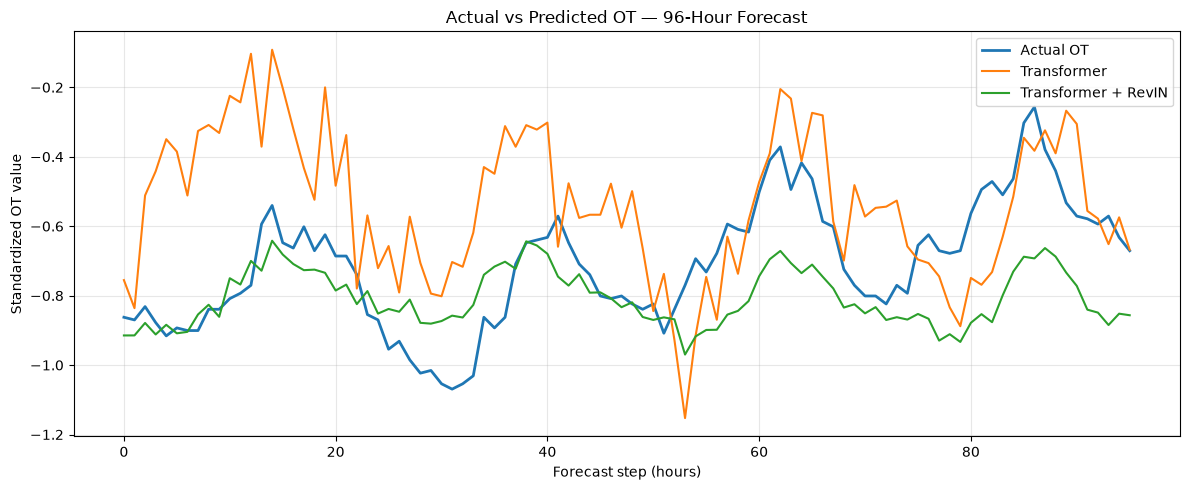

Saved plot: figures/Transformer_RevIN_Comparison_96h.png


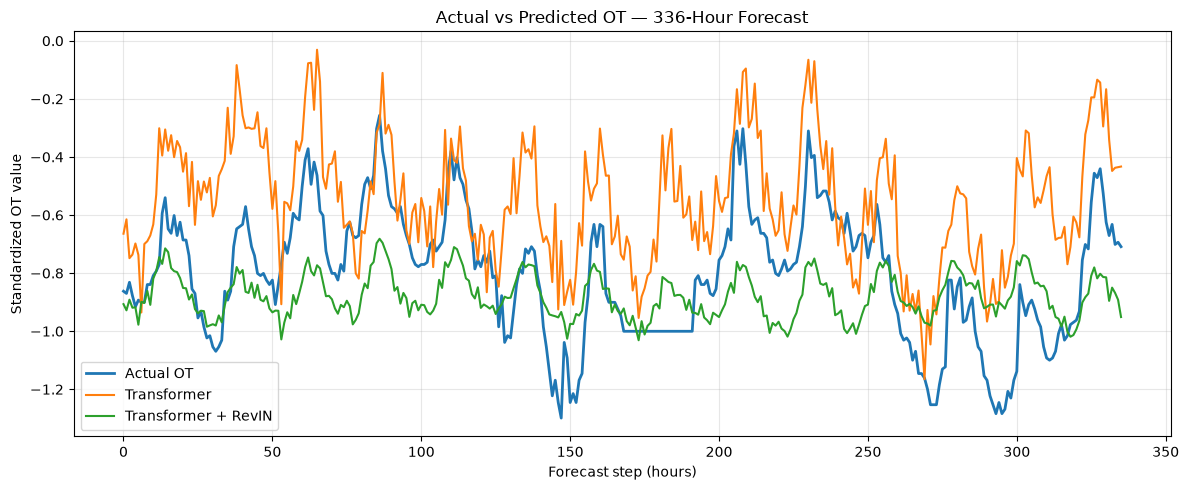

Saved plot: figures/Transformer_RevIN_Comparison_336h.png


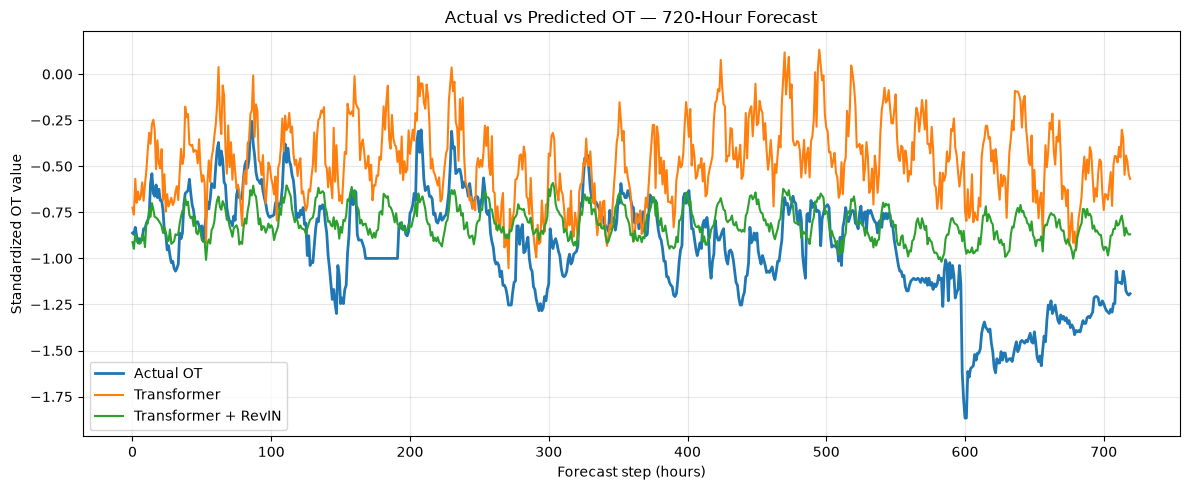

Saved plot: figures/Transformer_RevIN_Comparison_720h.png

All forecast comparison plots have been created.


In [14]:

# Cell 13: Plot actual vs. predicted OT values for all six models

figures_dir = "figures"
os.makedirs(figures_dir, exist_ok=True)

for horizon in HORIZONS:
    # Get the test data for this forecast horizon.
    test_loader = data_loaders[horizon]["test"]
    X_test, y_test = next(iter(test_loader))

    # Use the first test example for a clear forecast plot.
    X_sample = X_test[:1].to(device)
    y_actual = y_test[0].cpu().numpy()

    plt.figure(figsize=(12, 5))

    # Plot the actual future OT values.
    plt.plot(
        range(horizon),
        y_actual,
        label="Actual OT",
        linewidth=2,
    )

    for variant_name, variant_config in VARIANTS.items():
        if variant_name == "Transformer":
            checkpoint_path = os.path.join(
                MODELS_DIR,
                f"Transformer_{horizon}h_best.pt",
            )
        else:
            checkpoint_path = os.path.join(
                MODELS_DIR,
                f"Transformer_RevIN_{horizon}h_best.pt",
            )

        model = TransformerForecaster(
            input_dim=7,
            input_len=96,
            pred_len=horizon,
            use_revin=variant_config["use_revin"],
            **MODEL_CONFIG,
        ).to(device)

        model.load_state_dict(
            torch.load(
                checkpoint_path,
                map_location=device,
                weights_only=True,
            )
        )
        model.eval()

        with torch.no_grad():
            prediction = model(X_sample)[0].cpu().numpy()

        plt.plot(
            range(horizon),
            prediction,
            label=variant_name,
            linewidth=1.5,
        )

        del model

    plt.title(f"Actual vs Predicted OT — {horizon}-Hour Forecast")
    plt.xlabel("Forecast step (hours)")
    plt.ylabel("Standardized OT value")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plot_path = os.path.join(
        figures_dir,
        f"Transformer_RevIN_Comparison_{horizon}h.png",
    )

    plt.savefig(plot_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved plot:", plot_path)

print("\nAll forecast comparison plots have been created.")


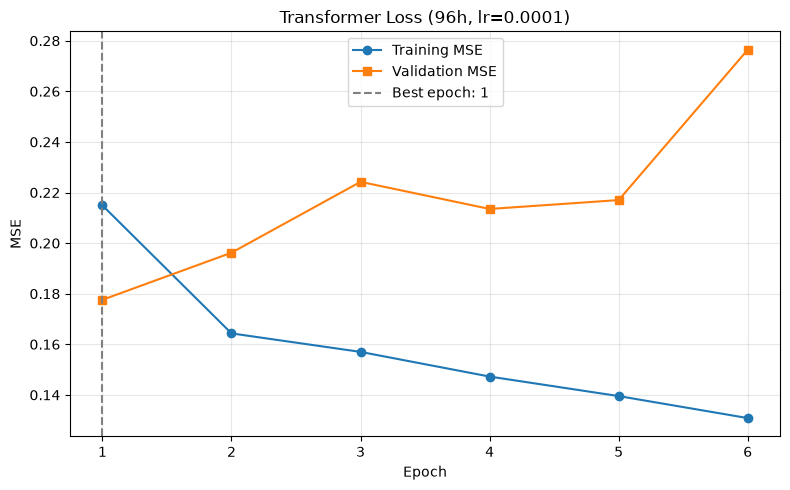

Saved: figures/Transformer_96h_Loss.png


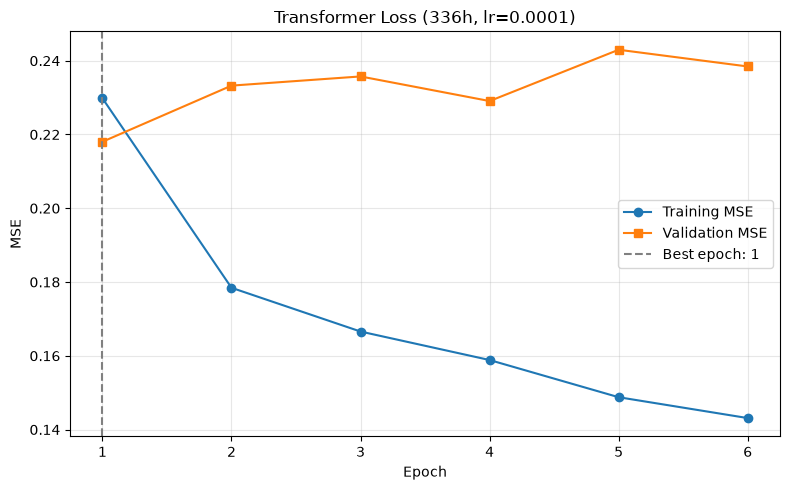

Saved: figures/Transformer_336h_Loss.png


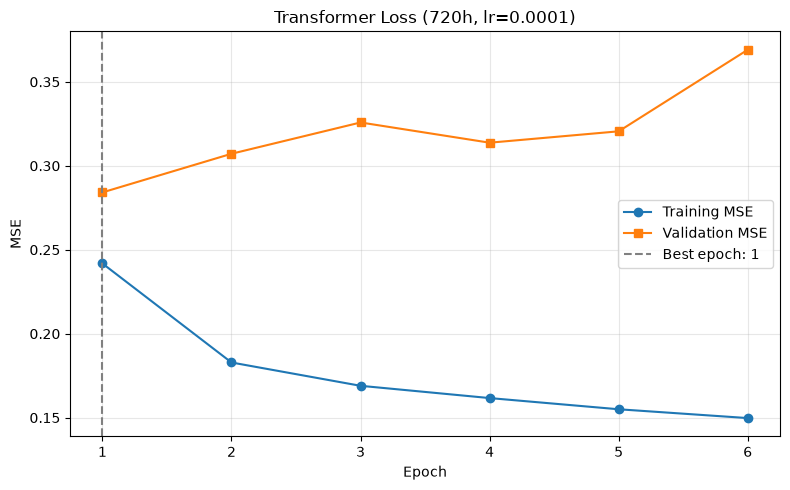

Saved: figures/Transformer_720h_Loss.png


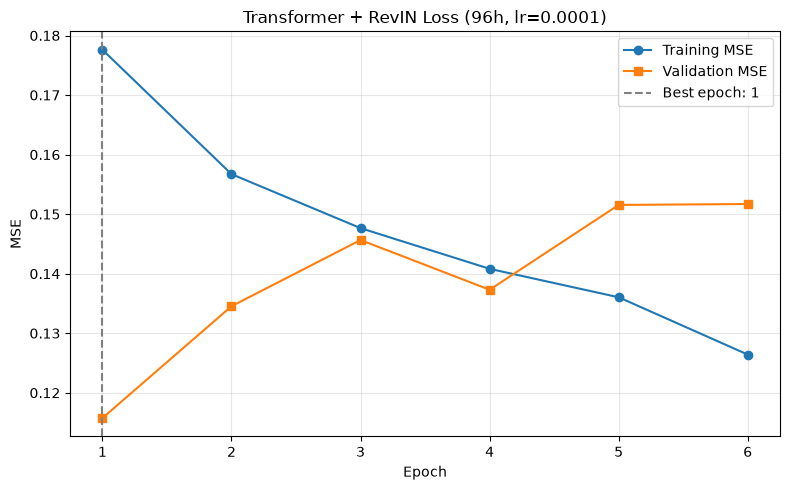

Saved: figures/Transformer_RevIN_96h_Loss.png


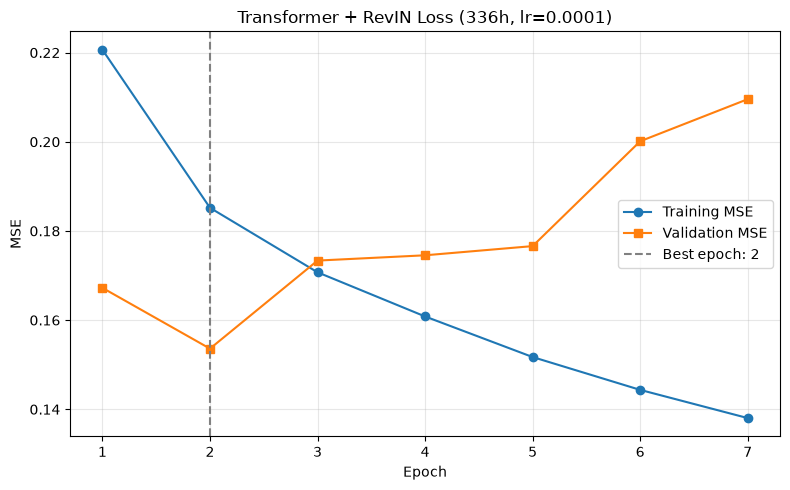

Saved: figures/Transformer_RevIN_336h_Loss.png


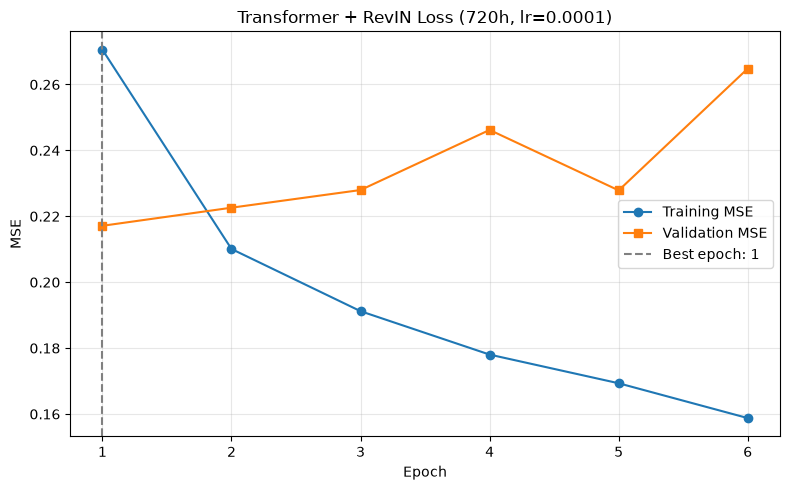

Saved: figures/Transformer_RevIN_720h_Loss.png

All six updated loss plots created successfully.


In [15]:

# Cell 13b: Create updated loss plots for all six model runs

for _, row in final_training_df.iterrows():

    train_losses = row["train_losses"]
    val_losses = row["val_losses"]
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        train_losses,
        marker="o",
        label="Training MSE",
    )

    plt.plot(
        epochs,
        val_losses,
        marker="s",
        label="Validation MSE",
    )

    plt.axvline(
        row["best_epoch"],
        linestyle="--",
        color="gray",
        label=f"Best epoch: {row['best_epoch']}",
    )

    plt.title(
        f"{row['model']} Loss "
        f"({row['pred_len']}h, lr={row['learning_rate']})"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    if "RevIN" in row["model"]:
        tag = "Transformer_RevIN"
    else:
        tag = "Transformer"

    plot_path = os.path.join(
        FIGURES_DIR,
        f"{tag}_{row['pred_len']}h_Loss.png",
    )

    plt.savefig(plot_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", plot_path)

print("\nAll six updated loss plots created successfully.")


In [16]:

# Cell 14: Check saved project outputs

print("=== RESULTS ===")
for filename in sorted(os.listdir("results")):
    print(filename)

print("\n=== SAVED MODELS ===")
for filename in sorted(os.listdir("saved_models")):
    if filename.endswith(".pt"):
        print(filename)

print("\n=== FIGURES ===")
for filename in sorted(os.listdir("figures")):
    if filename.endswith(".png"):
        print(filename)


=== RESULTS ===
DLinear_ETTh1_336h_results.csv
DLinear_ETTh1_720h_results.csv
DLinear_ETTh1_lr0.0001_run2_results.csv
DLinear_ETTh1_results.csv
Final_Model_Comparison_3Models.csv
Final_Model_Comparison_5Models.csv
Final_Model_Rankings_5Models.csv
Forecasting_Model_Comparison.csv
LSTM_336h_simple_results.csv
LSTM_720h_simple_results.csv
LSTM_96h_Validation_Comparison.csv
LSTM_96h_initial_results.csv
LSTM_96h_simple_results.csv
LSTM_All_Horizons_Results.csv
Persistence_All_Horizons.csv
Training_Time_Comparison_Available.csv
Transformer_All_Horizons.csv

=== SAVED MODELS ===
DLinear_ETTh1_336h_best.pt
DLinear_ETTh1_720h_best.pt
DLinear_ETTh1_best.pt
DLinear_ETTh1_lr0.0001_run2.pt
DLinear_ETTh1_lr0.001_run1.pt
Transformer_336h_best.pt
Transformer_720h_best.pt
Transformer_96h_best.pt
Transformer_RevIN_336h_best.pt
Transformer_RevIN_720h_best.pt
Transformer_RevIN_96h_best.pt
Transformer_Transformer_96h_lr0.0001_selection.pt
Transformer_Transformer_96h_lr0.001_selection.pt
Transformer_Transfo